# **Car Insurance Claim Risk Prediction: Machine Learning, GLM and Generalist Models for Underwriting and Fraud-Risk Triage**

# **Part 1 - Business Problem**

**Context.** An auto insurer must decide, at policy issuance and renewal, how likely each policyholder is to file a claim in the next 6 months. Today, pricing and underwriting rely on static rules and broad actuarial tables, which can't capture the interaction between policyholder profile (age, tenure, city density), vehicle characteristics (make, model, engine, safety features, NCAP rating) and claim behavior. The result is mispriced policies, avoidable loss ratio, and manual reviews that are not prioritized by risk.

**Objective.** Build a binary classification model that estimates the probability of `is_claim` for each policyholder. The score will be used to:

- Support risk-based pricing and underwriting decisions.
- Prioritize high-risk policies for manual review and fraud-risk triage.
- Reduce loss ratio without rejecting good customers unnecessarily.

**Statistical (GLM) approach.**

- Poisson GLM with a log link and a log exposure offset (`policy_tenure`), the standard actuarial approach to claim frequency, with robust standard errors (modified Poisson) because the target is binary.
- Incidence rate ratios (IRR) for each risk factor, so underwriters and pricing teams can read the effect of each variable in business terms.
- Binomial (logit) GLM as a benchmark, to compare discrimination and calibration against the Poisson model.

**Machine learning approach.**

- Baselines: Poisson GLM, Logistic Regression and Decision Tree.
- Tree ensembles and gradient boosting: Random Forest, XGBoost, LightGBM and CatBoost, which handle categorical features well.
- Class imbalance handling (the positive class is rare): class weights, resampling and threshold tuning.
- Probability calibration, so the score can be used for pricing.
- Model comparison: interpretable GLMs against boosted models on the same validation scheme, to measure how much predictive lift is gained over the actuarial standard.

**Generalist models approach.**

- A tabular foundation model (such as TabPFN) as a strong benchmark with no manual tuning.
- An LLM as an explanation layer: it turns each score and its top SHAP drivers into a plain-language justification for underwriters and analysts.
- An LLM as a triage assistant: it summarizes the risk profile of flagged policies to speed up manual review.
- Safe use: the LLM does not make the decision. It only explains and summarizes the outputs of the validated ML model, with no personal data sent to external APIs and with human review.

**Success metrics.** PR-AUC and ROC-AUC (the main metrics given the imbalance), Recall and Precision at the chosen threshold, F1, calibration (Brier score and observed vs predicted claim rate), and estimated business impact (claims captured in the top decile of risk).

**Dataset note.** The target `is_claim` indicates whether a claim was filed, not whether the claim was fraudulent. There is no fraud label in the data, so the project is framed as claim risk prediction, with fraud-risk triage as a downstream use of the score.

In [ ]:
import sys
import os 
import pathlib
import joblib
import time
import joblib
from tqdm.auto import tqdm
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
import numpy as np
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier, RandomForestClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import auc, roc_curve

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

# Part 2 - Database

In [2]:
# Load the treated dataset
df = pd.read_csv(r"C:\Users\rafae\Documents\Projetos_data_science_IA\machine_learning\Car Insurance Claim Prediction\data\train_tratado_zscore.csv")
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622.0,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738.0,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,ID58588,0.355089,0.13,0.644231,C8,8794.0,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794.0,1,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,5,Electric,4.8,3845,1735,1530,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0


In [3]:
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622.0,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738.0,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


In [4]:
df.tail()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
58587,ID58588,0.355089,0.13,0.644231,C8,8794.0,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738.0,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794.0,1,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,5,Electric,4.8,3845,1735,1530,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
58591,ID58592,0.124429,0.02,0.442308,C8,8794.0,3,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,6,Power,5.2,4300,1790,1635,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0


In [5]:
df.shape

(58592, 44)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 44 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  str    
 1   policy_tenure                     58592 non-null  float64
 2   age_of_car                        58592 non-null  float64
 3   age_of_policyholder               58592 non-null  float64
 4   area_cluster                      58592 non-null  str    
 5   population_density                58592 non-null  float64
 6   make                              58592 non-null  int64  
 7   segment                           58592 non-null  str    
 8   model                             58592 non-null  str    
 9   fuel_type                         58592 non-null  str    
 10  max_torque                        58592 non-null  str    
 11  max_power                         58592 non-null  str    
 12  engine_type    

In [7]:
df.dtypes

policy_id                               str
policy_tenure                       float64
age_of_car                          float64
age_of_policyholder                 float64
area_cluster                            str
population_density                  float64
make                                  int64
segment                                 str
model                                   str
fuel_type                               str
max_torque                              str
max_power                               str
engine_type                             str
airbags                               int64
is_esc                                  str
is_adjustable_steering                  str
is_tpms                                 str
is_parking_sensors                      str
is_parking_camera                       str
rear_brakes_type                        str
displacement                          int64
cylinder                              int64
transmission_type               

# Part 3 - Pre-processamento dados

In [8]:
# null count per column, only columns with nulls / contagem de nulos por coluna, só as que têm
nulos = df.isna().sum()
nulos[nulos > 0].to_frame("nulos")

# duplicated rows and duplicated identifiers / linhas duplicadas e identificadores duplicados
print("linhas duplicadas / duplicated rows:", df.duplicated().sum())
print("policy_id repetidos / repeated ids:", df["policy_id"].duplicated().sum())

linhas duplicadas / duplicated rows: 0
policy_id repetidos / repeated ids: 0


In [9]:
# unique values per text column, n visible / valores únicos por coluna de texto, com n visível
texto = df.select_dtypes(exclude="number").drop(columns="policy_id")
pd.DataFrame({
    "n_unicos": texto.nunique(),
    "exemplos": texto.apply(lambda s: s.unique()[:4].tolist()),
})

,n_unicos,exemplos
area_cluster,22,"[C1, C2, C3, C4]"
segment,6,"[A, C1, C2, B2]"
model,11,"[M1, M2, M3, M4]"
fuel_type,3,"[CNG, Petrol, Diesel]"
max_torque,9,"[60Nm@3500rpm, 113Nm@4400rpm, 91Nm@4250rpm, 25..."
max_power,9,"[40.36bhp@6000rpm, 88.50bhp@6000rpm, 67.06bhp@..."
engine_type,11,"[F8D Petrol Engine, 1.2 L K12N Dualjet, 1.0 SC..."
is_esc,2,"[No, Yes]"
is_adjustable_steering,2,"[No, Yes]"
is_tpms,2,"[No, Yes]"


In [10]:
# type, null count, unique values and example per column / tipo, nulos, valores únicos e exemplo por coluna
tipos = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "n_unicos": df.nunique(),
    "exemplo": df.iloc[0],
})
tipos

,tipo,nulos,n_unicos,exemplo
policy_id,str,0,58592,ID00001
policy_tenure,float64,0,58592,0.515874
age_of_car,float64,0,25,0.05
age_of_policyholder,float64,0,59,0.644231
area_cluster,str,0,22,C1
population_density,float64,0,22,4990.0
make,int64,0,5,1
segment,str,0,6,A
model,str,0,11,M1
fuel_type,str,0,3,CNG


In [11]:
# how many columns per type / quantas colunas por tipo
df.dtypes.astype(str).value_counts().to_frame("colunas")

,colunas
str,28
int64,11
float64,5


# Part 4 - Limpeza de dados 

In [12]:
# null count and share per column / contagem e proporção de nulos por coluna
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "pct": (df.isna().mean() * 100).round(2),
})

print("n =", len(df), "| colunas com nulos / columns with nulls:", int((nulos["nulos"] > 0).sum()))
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

n = 58592 | colunas com nulos / columns with nulls: 0


,nulos,pct


In [13]:
# rows with at least one null / linhas com pelo menos um nulo
linhas_nulas = df.isna().any(axis=1)
print("linhas afetadas / affected rows:", int(linhas_nulas.sum()), f"({linhas_nulas.mean() * 100:.2f}%)")

linhas afetadas / affected rows: 0 (0.00%)


In [14]:
# placeholder strings that mean "missing" / textos que significam "ausente"
ausentes = {"", " ", "na", "n/a", "nan", "null", "none", "unknown", "?", "-"}

# count placeholders per text column / conta esses textos por coluna de texto
texto = df.select_dtypes(exclude="number")
disfarcados = texto.apply(lambda s: s.astype(str).str.strip().str.lower().isin(ausentes).sum())

disfarcados[disfarcados > 0].to_frame("valores_ausentes_disfarcados")

,valores_ausentes_disfarcados


In [15]:
# zeros in numeric columns, n visible / zeros em colunas numéricas, com n visível
num = df.select_dtypes("number")
zeros = (num == 0).sum()
zeros[zeros > 0].to_frame("zeros")

,zeros
age_of_car,5257
ncap_rating,19097
is_claim,54844


In [16]:
# repeated identifiers and fully repeated rows / identificadores repetidos e linhas totalmente repetidas
print("n =", len(df))
print("policy_id repetidos / repeated ids:", df["policy_id"].duplicated().sum())
print("linhas duplicadas / duplicated rows:", df.duplicated().sum())

n = 58592
policy_id repetidos / repeated ids: 0
linhas duplicadas / duplicated rows: 0


In [17]:
# rows identical in every column except the identifier / linhas iguais em todas as colunas, exceto o identificador
cols_sem_id = df.columns.drop("policy_id")
dup_sem_id = df.duplicated(subset=cols_sem_id, keep=False)

print("linhas envolvidas / rows involved:", int(dup_sem_id.sum()), f"({dup_sem_id.mean() * 100:.2f}%)")

linhas envolvidas / rows involved: 0 (0.00%)


In [18]:
# do identical rows agree on the target? / as linhas idênticas concordam no alvo?
grupos = df[dup_sem_id].groupby(list(cols_sem_id.drop("is_claim")))["is_claim"].agg(["count", "nunique"])
print("grupos de linhas idênticas / groups:", len(grupos))
print("grupos com alvo diferente / groups with conflicting target:", int((grupos["nunique"] > 1).sum()))

grupos de linhas idênticas / groups: 0
grupos com alvo diferente / groups with conflicting target: 0


# **Part 5 - Feature Engineering**

In [19]:
from sklearn.preprocessing import LabelEncoder

# columns before encoding, to prove none is added / colunas antes da codificação, para provar que nenhuma é adicionada
cols_antes = df.columns.tolist()

# every text column except the identifier, plus make (brand code) / toda coluna de texto exceto o identificador, mais make (código de marca)
cat_cols = df.select_dtypes(exclude="number").columns.drop("policy_id").tolist() + ["make"]

print(len(cat_cols), "colunas / columns")
df[cat_cols].nunique().sort_values().to_frame("n_categorias").T

28 colunas / columns


,is_esc,is_front_fog_lights,transmission_type,rear_brakes_type,is_parking_camera,is_parking_sensors,is_tpms,is_adjustable_steering,is_driver_seat_height_adjustable,is_power_steering,is_central_locking,is_power_door_locks,is_brake_assist,is_rear_window_defogger,is_rear_window_washer,is_rear_window_wiper,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,fuel_type,steering_type,make,segment,max_torque,max_power,model,engine_type,area_cluster
n_categorias,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,3,3,5,6,9,9,11,11,22


In [20]:
# encode in place, one encoder per column kept for the Kaggle test set / codifica no lugar, um encoder por coluna guardado para o teste do Kaggle
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    encoders[col] = le

# View the encoders / Veja os codificadores
le    

Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Holds the label for each class.","ndarray[object](5,)","['1','2','3','4','5']"


In [21]:
# same columns in the same order / mesmas colunas na mesma ordem
print("colunas iguais / same columns:", df.columns.tolist() == cols_antes)
print("formato / shape:", df.shape)

# text columns left, expected only the identifier / colunas de texto que sobraram, esperado só o identificador
print(df.select_dtypes(exclude="number").columns.tolist())

colunas iguais / same columns: True
formato / shape: (58592, 44)
['policy_id']


In [22]:
# mapping category to number, example with fuel_type / mapeamento categoria para número, exemplo com fuel_type
le = encoders["fuel_type"]
dict(zip(le.classes_, le.transform(le.classes_)))

{'CNG': np.int64(0), 'Diesel': np.int64(1), 'Petrol': np.int64(2)}

In [23]:
# encoded values per column, a quick sanity check / valores codificados por coluna, checagem rápida
df[["fuel_type", "segment", "is_esc", "max_torque", "area_cluster"]].head()

,fuel_type,segment,is_esc,max_torque,area_cluster
0,0,0,0,5,0
1,0,0,0,5,11
2,0,0,0,5,15
3,2,3,1,0,16
4,2,0,0,8,17


In [ ]:
# Save the encoders for later use, e.g. for the Kaggle test set / Salva os codificadores para uso posterior, ex. para o teste do Kaggle

# save the encoders for the Kaggle test set / salva os encoders para o teste do Kaggle
joblib.dump(encoders, r"C:\Users\rafae\Documents\Projetos_data_science_IA\machine_learning\Car Insurance Claim Prediction\models\label_encoders.joblib")

['C:\\Users\\rafae\\Documents\\Projetos_data_science_IA\\machine_learning\\Car Insurance Claim Prediction\\models\\label_encoders.joblib']

In [25]:
# View the encoders / Veja os codificadores
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,0,4990.0,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
1,ID00002,0.672619,0.02,0.375000,11,27003.0,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
2,ID00003,0.841110,0.02,0.384615,15,4076.0,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
3,ID00004,0.900277,0.11,0.432692,16,21622.0,0,3,3,2,0,6,2,2,1,1,0,1,1,1,1197,4,0,5,0,4.8,3995,1735,1515,1335,1,0,0,1,1,1,1,1,1,1,1,1,2,0
4,ID00005,0.596403,0.11,0.634615,17,34738.0,1,0,4,2,8,5,0,2,0,0,0,0,1,1,999,3,0,5,0,5.0,3731,1579,1490,1155,0,0,0,0,0,1,1,1,0,1,1,1,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,ID58588,0.355089,0.13,0.644231,20,8794.0,1,0,4,2,8,5,0,2,0,0,0,0,1,1,999,3,0,5,0,5.0,3731,1579,1490,1155,0,0,0,0,0,1,1,1,0,1,1,1,2,0
58588,ID58589,1.199642,0.02,0.519231,5,7788.0,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
58589,ID58590,1.162273,0.05,0.451923,17,34738.0,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
58590,ID58591,1.236307,0.14,0.557692,20,8794.0,0,2,7,2,0,6,8,2,0,1,0,1,0,1,1197,4,1,5,0,4.8,3845,1735,1530,1335,1,0,0,0,1,1,1,1,1,1,1,1,2,0


# Part 7 - Selecionando variavel x y

In [48]:
# policy_id is an identifier, not a predictor / policy_id é identificador, não preditor
X = df.drop(["is_claim", "policy_id"], axis=1)
y = df["is_claim"]

In [32]:
print("X:", X.shape, "| y:", y.shape)
X.dtypes.value_counts().to_frame("colunas")

X: (58592, 43) | y: (58592,)


,colunas
int64,37
float64,5
str,1


In [49]:
print("X:", X.shape, "| y:", y.shape)
X.dtypes.to_frame("tipo").T

X: (58592, 42) | y: (58592,)


,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating
tipo,float64,float64,float64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


# **Part 8 - Divisão treino e teste**

In [ ]:
"""Validation split without SMOTE / split de validação sem SMOTE."""

# train and test split / divisão em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,  # 20% for testing / 20% para teste
    random_state=42  # reproducibility / reprodutibilidade
)

# validation carved out of train, test stays untouched / validação separada do treino, teste fica intacto
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,  # 20% of train for validation / 20% do treino para validação
    random_state=42  # reproducibility / reprodutibilidade

)

In [60]:
# check shapes / verifica os formatos
print(X_tr.shape, X_val.shape)

(37498, 42) (9375, 42)


In [61]:
# columns must match across splits / as colunas devem coincidir entre os splits
print(X_tr.columns.equals(X_val.columns))
print(X_tr.shape, X_val.shape, X_test.shape)

True
(37498, 42) (9375, 42) (11719, 42)


# Part 9 - Modelos Machine learning 

In [ ]:
"""Compare 10 machine learning models / compara 10 modelos de machine learning."""

# 10 models, shallow trees to limit overfitting on synthetic rows / 10 modelos, árvores rasas para limitar o overfitting em linhas sintéticas
"""Class weight instead of SMOTE / peso de classe no lugar do SMOTE."""

# imbalance ratio of the target / razão de desbalanceamento do alvo
peso_pos = (y_tr == 0).sum() / (y_tr == 1).sum()

modelos = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=30, class_weight="balanced", n_jobs=-1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, max_depth=8, min_samples_leaf=30, class_weight="balanced", n_jobs=-1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=peso_pos, eval_metric="aucpr", n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, class_weight="balanced", n_jobs=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=300, learning_rate=0.05, depth=4, auto_class_weights="Balanced", random_seed=42, verbose=0),
}

# share of policies flagged by ranking / proporção de apólices marcadas por ranking
frac_alerta = 0.20

resultados = []
probas_val = {}

barra = tqdm(modelos.items(), total=len(modelos), desc="Models / modelos")
for nome, modelo in barra:
    
    # current model on the bar / modelo atual na barra
    barra.set_postfix_str(f"treinando / training: {nome}")
    inicio = time.time()

    # train on original data, no resampling / treina nos dados originais, sem reamostragem
    modelo.fit(X_tr, y_tr)

    # probability of claim on the untouched validation set / probabilidade de sinistro na validação intacta
    proba = modelo.predict_proba(X_val)[:, 1]
    probas_val[nome] = proba

    # flag the top 20% by rank, ties cannot enlarge the group / marca os 20% maiores por ranking, empates não aumentam o grupo
    pred = np.zeros(len(proba), dtype=int)
    pred[np.argsort(-proba, kind="stable")[: int(frac_alerta * len(proba))]] = 1

    resultados.append({
        "modelo": nome,
        "roc_auc": roc_auc_score(y_val, proba),
        "pr_auc": average_precision_score(y_val, proba),
        "acuracia": accuracy_score(y_val, pred),
        "acuracia_balanceada": balanced_accuracy_score(y_val, pred),
        "recall": recall_score(y_val, pred),
        "precisao": precision_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "brier": brier_score_loss(y_val, proba),
        "segundos": time.time() - inicio,
    })
    tqdm.write(f"{nome}: PR-AUC = {resultados[-1]['pr_auc']:.4f} | {resultados[-1]['segundos']:.0f}s")

Models / modelos:  20%|██        | 2/10 [00:00<00:01,  7.82it/s, treinando / training: Random Forest]      

Logistic Regression: PR-AUC = 0.0906 | 0s
Decision Tree: PR-AUC = 0.1000 | 0s


Models / modelos:  30%|███       | 3/10 [00:01<00:04,  1.48it/s, treinando / training: Extra Trees]  

Random Forest: PR-AUC = 0.1055 | 1s


Models / modelos:  40%|████      | 4/10 [00:02<00:04,  1.28it/s, treinando / training: AdaBoost]   

Extra Trees: PR-AUC = 0.0912 | 1s


Models / modelos:  50%|█████     | 5/10 [00:10<00:16,  3.31s/it, treinando / training: Gradient Boosting]

AdaBoost: PR-AUC = 0.1003 | 8s


Models / modelos:  60%|██████    | 6/10 [00:28<00:33,  8.39s/it, treinando / training: HistGradientBoosting]

Gradient Boosting: PR-AUC = 0.1040 | 18s


Models / modelos:  70%|███████   | 7/10 [00:29<00:18,  6.11s/it, treinando / training: XGBoost]             

HistGradientBoosting: PR-AUC = 0.1071 | 1s


Models / modelos:  80%|████████  | 8/10 [00:31<00:09,  4.52s/it, treinando / training: LightGBM]

XGBoost: PR-AUC = 0.1008 | 1s


Models / modelos:  90%|█████████ | 9/10 [00:32<00:03,  3.55s/it, treinando / training: CatBoost]

LightGBM: PR-AUC = 0.1018 | 1s


Models / modelos: 100%|██████████| 10/10 [00:36<00:00,  3.63s/it, treinando / training: CatBoost]

CatBoost: PR-AUC = 0.1062 | 4s


In [ ]:
"""Ranked model results with lift over chance / resultados dos modelos com lift sobre o acaso."""

# ranked results by PR-AUC / resultados ordenados por PR-AUC
tabela = pd.DataFrame(resultados).sort_values("pr_auc", ascending=False).reset_index(drop=True)

# lift: precision in the flagged group over the base rate / lift: precisão no grupo marcado sobre a taxa base
tabela["lift"] = tabela["precisao"] / y_val.mean()

# chance level references / referências do nível do acaso
print(f"n validação = {len(y_val)} | acaso: PR-AUC = {y_val.mean():.4f}, ROC-AUC = 0.5, recall = {frac_alerta}, precisão = {y_val.mean():.4f}")

"""Print the ranked table as plain text / imprime a tabela ordenada como texto simples."""

# plain text output for easy copy and paste / saída em texto simples para copiar e colar
print(tabela.round(4).to_string())

n validação = 9375 | acaso: PR-AUC = 0.0658, ROC-AUC = 0.5, recall = 0.2, precisão = 0.0658
                 modelo  roc_auc  pr_auc  acuracia  acuracia_balanceada  recall  precisao      f1   brier  segundos    lift
0  HistGradientBoosting   0.6493  0.1071    0.7796               0.5777  0.3452    0.1136  0.1709  0.2241    1.3973  1.7261
1              CatBoost   0.6476  0.1062    0.7794               0.5769  0.3436    0.1131  0.1701  0.2217    3.7406  1.7180
2         Random Forest   0.6417  0.1055    0.7779               0.5708  0.3323    0.1093  0.1645  0.2230    1.3224  1.6613
3     Gradient Boosting   0.6454  0.1040    0.7779               0.5708  0.3323    0.1093  0.1645  0.0606   18.2423  1.6613
4              LightGBM   0.6341  0.1018    0.7734               0.5526  0.2982    0.0981  0.1477  0.2098    1.4012  1.4911
5               XGBoost   0.6371  0.1008    0.7741               0.5552  0.3031    0.0997  0.1501  0.2128    1.1193  1.5154
6              AdaBoost   0.6369  0.1003

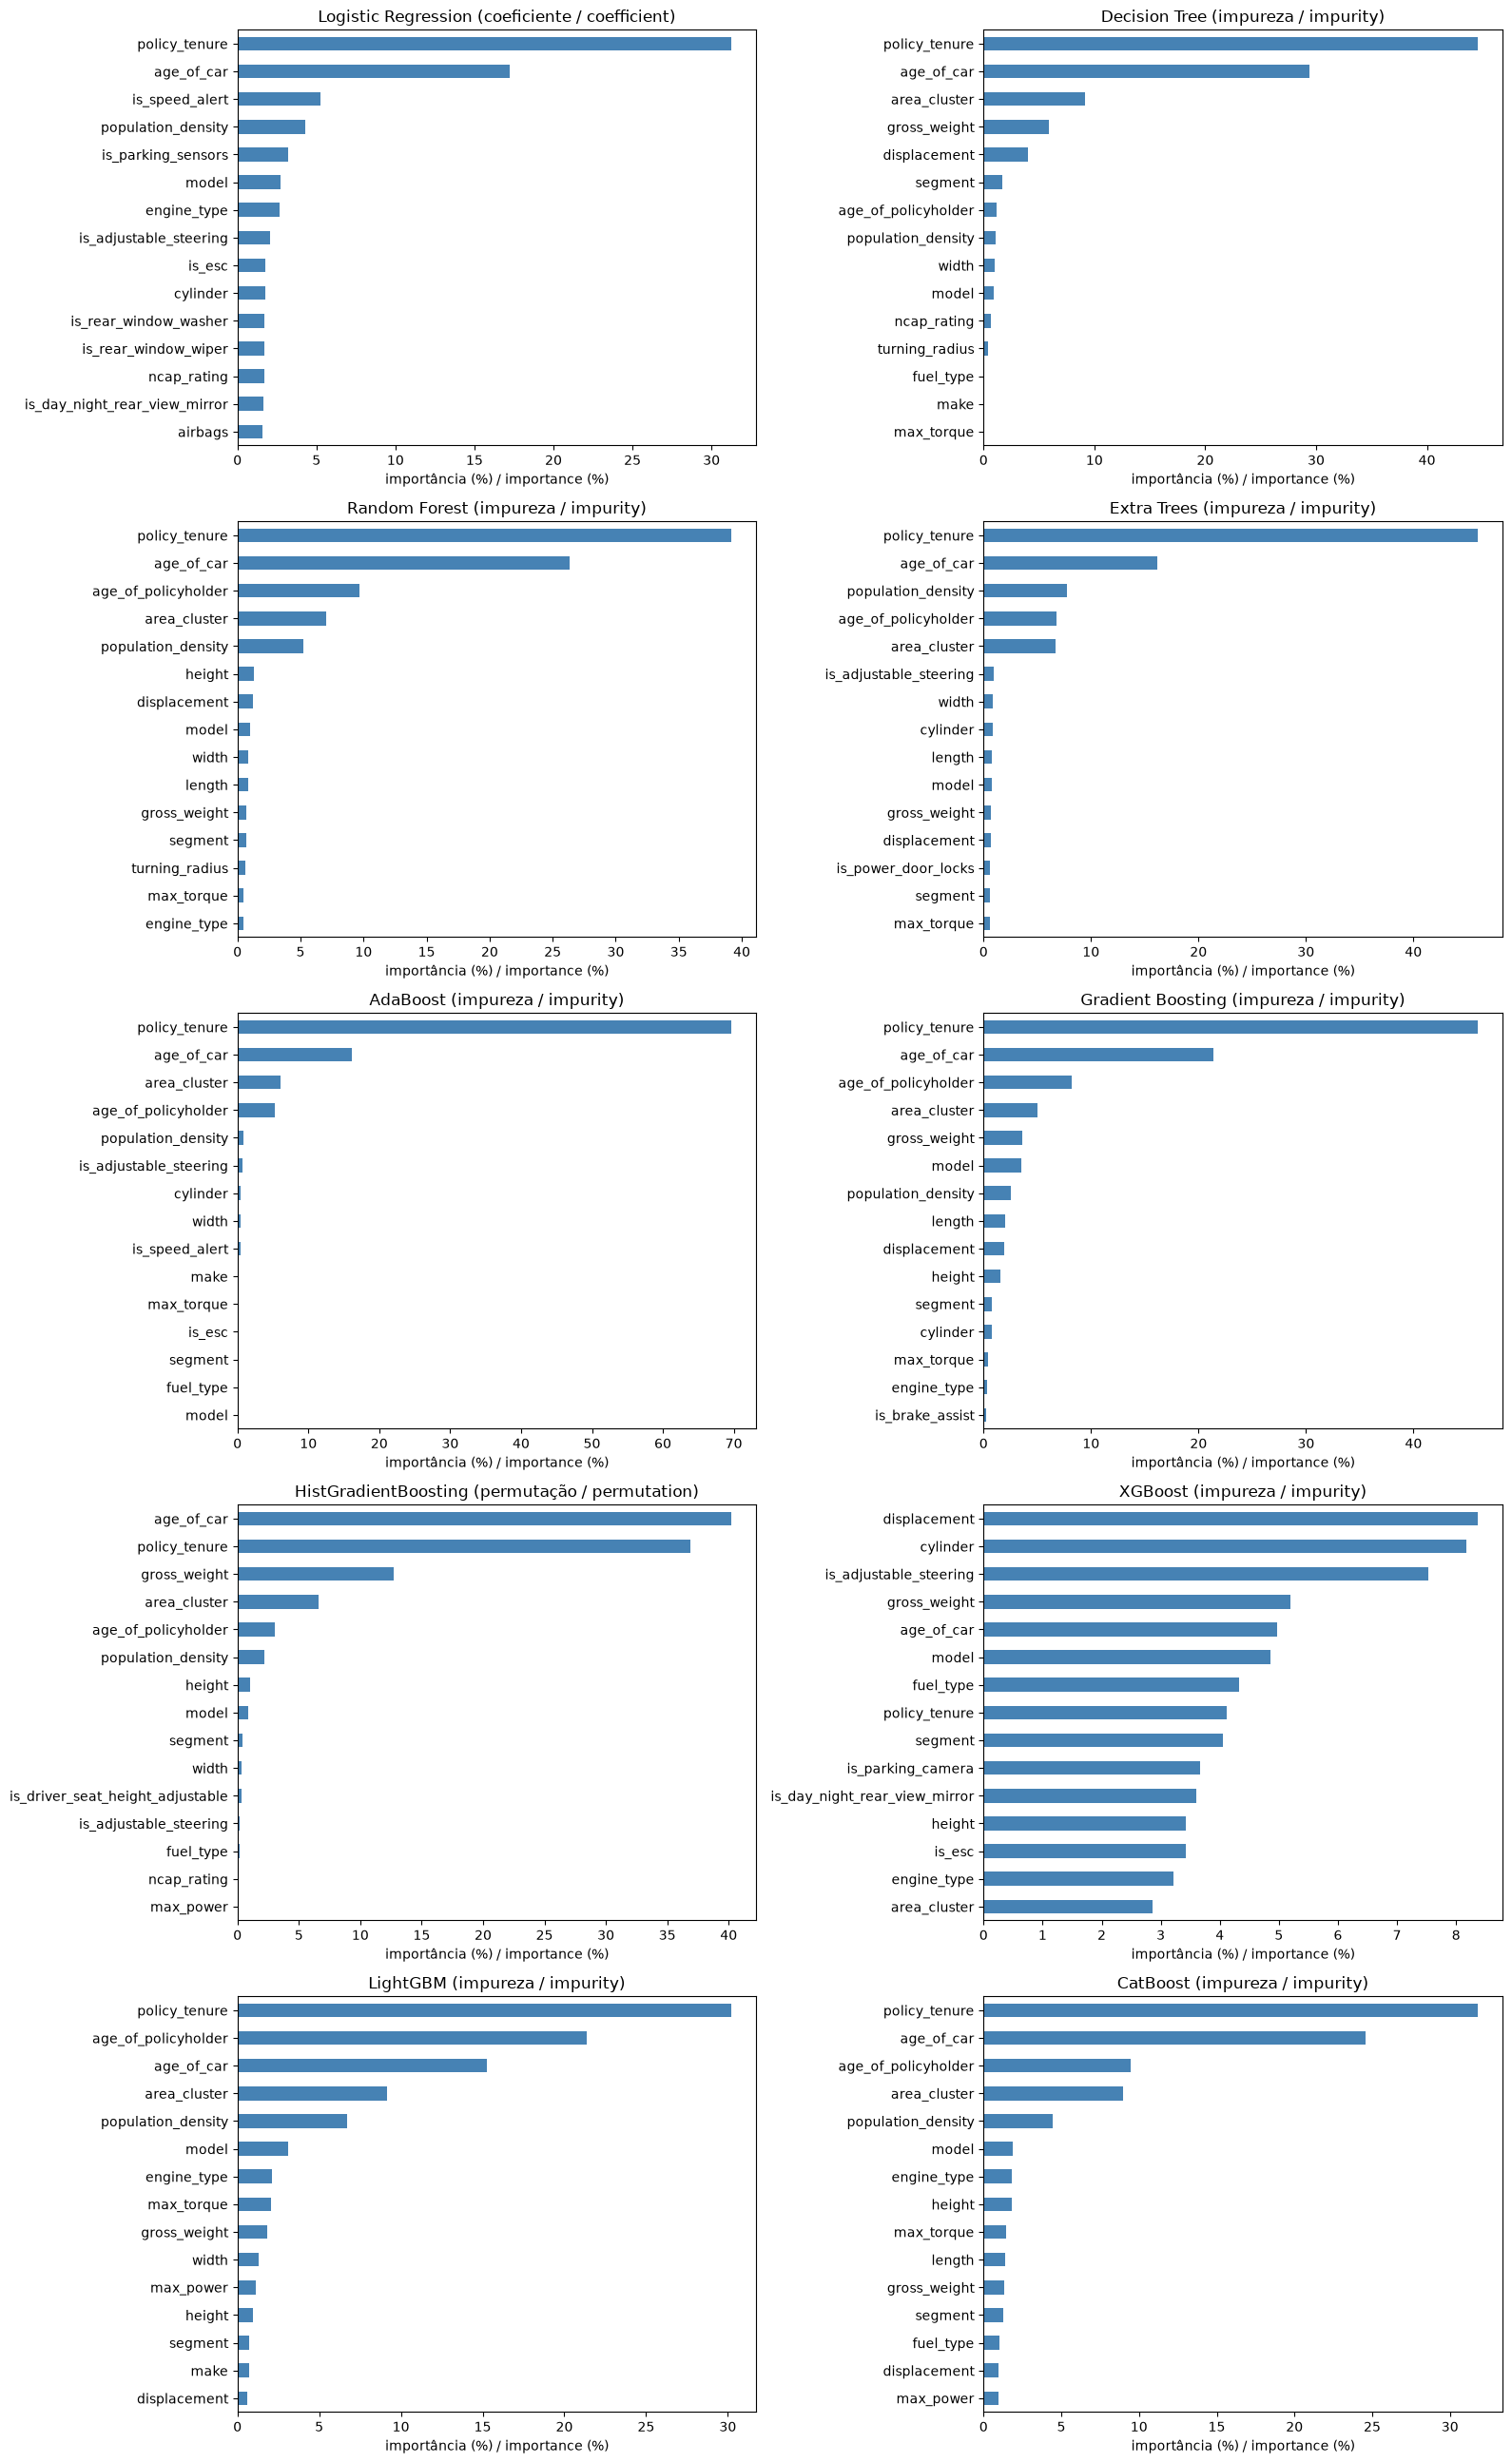

In [ ]:
"""Feature importance for all trained models / importância das variáveis de todos os modelos."""

# number of top features per plot / número de variáveis no topo de cada gráfico
top_n = 15

# grid of subplots, one per model / grade de gráficos, um por modelo
fig, eixos = plt.subplots(5, 2, figsize=(16, 26))
eixos = eixos.ravel()

importancias = {}

for eixo, (nome, modelo) in zip(eixos, modelos.items()):
    # tree models expose feature_importances_ directly / modelos de árvore expõem feature_importances_
    if hasattr(modelo, "feature_importances_"):
        valores = modelo.feature_importances_
        metodo = "impureza / impurity"

    # linear model inside a pipeline, use absolute scaled coefficients / modelo linear no pipeline, usa coeficientes absolutos escalados
    elif hasattr(modelo, "steps"):
        valores = np.abs(modelo[-1].coef_[0])
        metodo = "coeficiente / coefficient"

    # no native attribute, use permutation on validation / sem atributo nativo, usa permutação na validação
    else:
        perm = permutation_importance(
            modelo,
            X_val,
            y_val,
            scoring="average_precision",
            n_repeats=5,
            random_state=42,
            n_jobs=-1,
        )
        valores = perm.importances_mean
        metodo = "permutação / permutation"

    # normalize to percent so models are comparable / normaliza em percentual para comparar modelos
    serie = pd.Series(valores, index=X_tr.columns)
    serie = (serie / serie.sum() * 100).sort_values(ascending=False)
    importancias[nome] = serie

    # horizontal bar plot of the top features / barras horizontais das principais variáveis
    serie.head(top_n).sort_values().plot.barh(ax=eixo, color="steelblue")
    eixo.set_title(f"{nome} ({metodo})")
    eixo.set_xlabel("importância (%) / importance (%)")

# hide unused axes if any / esconde eixos não usados, se houver
for eixo in eixos[len(modelos):]:
    eixo.set_visible(False)

plt.tight_layout()
plt.show()

In [66]:
"""Average rank of each feature across models / ranking médio de cada variável entre os modelos."""

# rank 1 is the most important feature / ranking 1 é a variável mais importante
ranking = pd.DataFrame(importancias).rank(ascending=False)

# mean rank and mean importance per feature / ranking médio e importância média por variável
resumo = pd.DataFrame({
    "ranking_medio": ranking.mean(axis=1),
    "importancia_media_pct": pd.DataFrame(importancias).mean(axis=1),
}).sort_values("ranking_medio")

# show the top 15 / mostra as 15 primeiras
resumo.head(15).round(2)

,ranking_medio,importancia_media_pct
policy_tenure,1.80,37.98
age_of_car,2.30,21.16
area_cluster,7.10,6.25
population_density,7.20,3.72
age_of_policyholder,8.30,6.81
model,9.20,1.96
gross_weight,10.50,3.30
segment,14.10,1.09
height,14.65,1.17
is_adjustable_steering,15.70,1.23


# Part 10 - Métricas e avaliações

In [ ]:
"""Classification report for all models / relatório de classificação de todos os modelos."""

# share of policies flagged by ranking / proporção de apólices marcadas por ranking
frac_alerta = 0.20

relatorios = []

for nome in modelos:
    # validation probabilities saved in the training loop / probabilidades da validação salvas no loop de treino
    proba = probas_val[nome]

    # flag the top 20% by rank, same rule as before / marca os 20% maiores por ranking, mesma regra de antes
    pred = np.zeros(len(proba), dtype=int)
    pred[np.argsort(-proba, kind="stable")[: int(frac_alerta * len(proba))]] = 1

    # full report for the current model / relatório completo do modelo atual
    print(f"\n{nome}")
    print(
        classification_report(
            y_val,
            pred,
            target_names=["sem sinistro / no claim", "sinistro / claim"],
            digits=4,
            zero_division=0,
        )
    )

    # keep the claim class metrics for a summary table / guarda as métricas da classe sinistro para uma tabela resumo
    rel = classification_report(y_val, pred, output_dict=True, zero_division=0)["1"]
    relatorios.append({
        "modelo": nome,
        "precisao": rel["precision"],
        "recall": rel["recall"],
        "f1": rel["f1-score"],
        "suporte": rel["support"],
    })


Logistic Regression
                         precision    recall  f1-score   support

sem sinistro / no claim     0.9421    0.8068    0.8692      8758
       sinistro / claim     0.0976    0.2966    0.1469       617

               accuracy                         0.7732      9375
              macro avg     0.5199    0.5517    0.5081      9375
           weighted avg     0.8866    0.7732    0.8217      9375


Decision Tree
                         precision    recall  f1-score   support

sem sinistro / no claim     0.9420    0.8067    0.8691      8758
       sinistro / claim     0.0971    0.2950    0.1461       617

               accuracy                         0.7730      9375
              macro avg     0.5195    0.5508    0.5076      9375
           weighted avg     0.8864    0.7730    0.8215      9375


Random Forest
                         precision    recall  f1-score   support

sem sinistro / no claim     0.9451    0.8093    0.8719      8758
       sinistro / claim     0.10

In [68]:
"""Summary of the claim class across models / resumo da classe sinistro entre os modelos."""

# ranked by F1 of the claim class / ordenado pelo F1 da classe sinistro
resumo_relatorio = pd.DataFrame(relatorios).sort_values("f1", ascending=False).reset_index(drop=True)

# show the table / mostra a tabela
resumo_relatorio.round(4)

,modelo,precisao,recall,f1,suporte
0,HistGradientBoosting,0.1136,0.3452,0.1709,617.0
1,CatBoost,0.1131,0.3436,0.1701,617.0
2,Random Forest,0.1093,0.3323,0.1645,617.0
3,Gradient Boosting,0.1093,0.3323,0.1645,617.0
4,AdaBoost,0.1061,0.3225,0.1597,617.0
5,XGBoost,0.0997,0.3031,0.1501,617.0
6,LightGBM,0.0981,0.2982,0.1477,617.0
7,Logistic Regression,0.0976,0.2966,0.1469,617.0
8,Decision Tree,0.0971,0.2950,0.1461,617.0
9,Extra Trees,0.0912,0.2771,0.1372,617.0


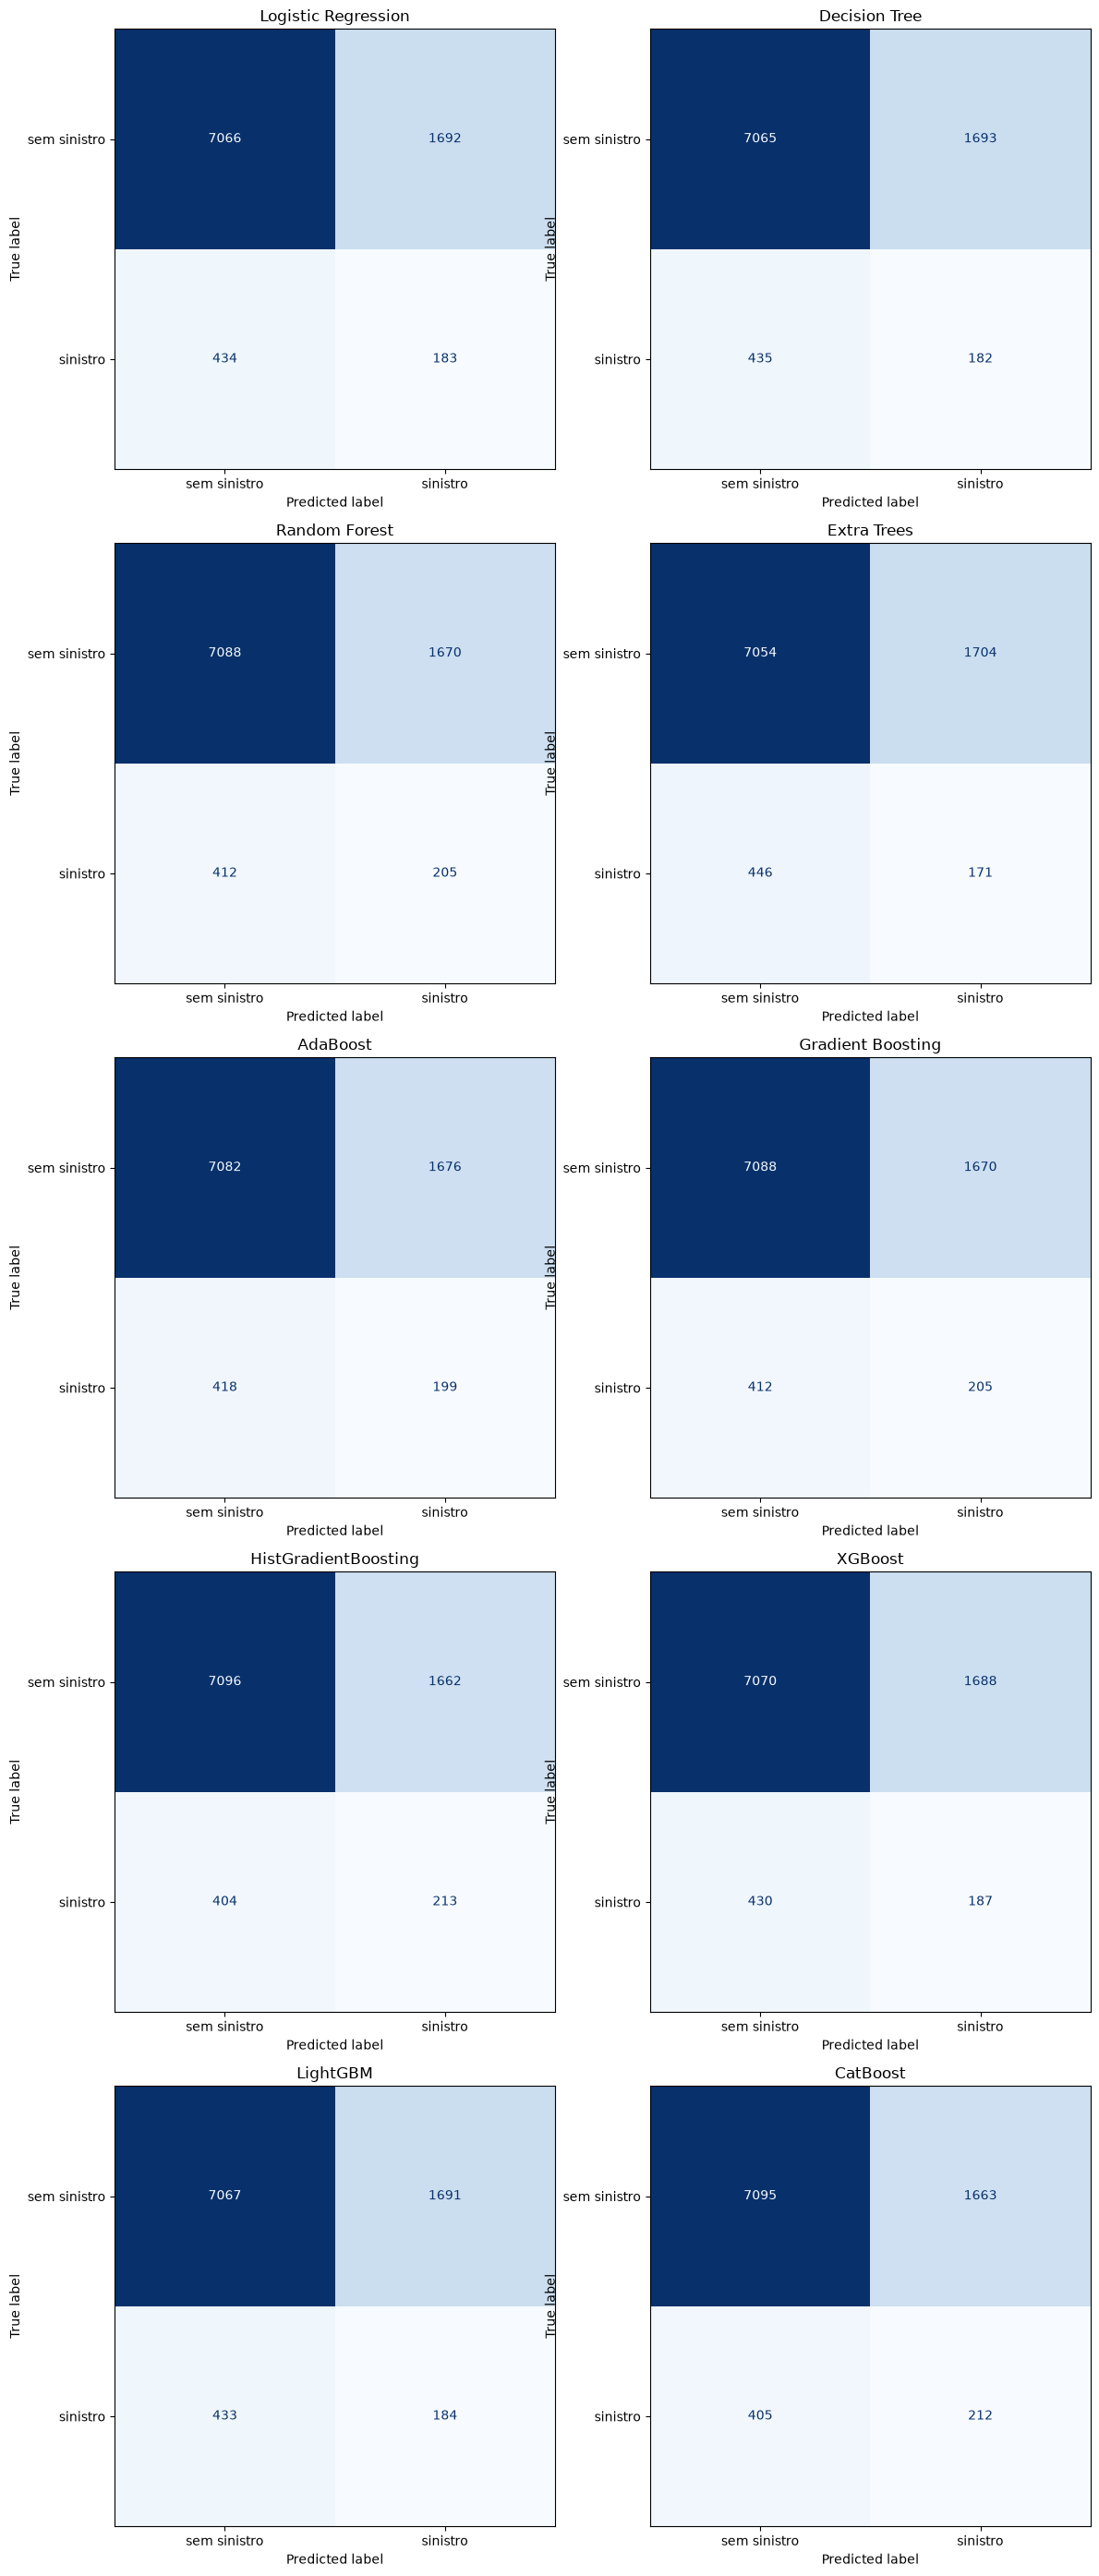

In [ ]:
"""Confusion matrix for all models / matriz de confusão de todos os modelos."""

# share of policies flagged by ranking / proporção de apólices marcadas por ranking
frac_alerta = 0.20

# grid of subplots, one per model / grade de gráficos, um por modelo
fig, eixos = plt.subplots(5, 2, figsize=(12, 28))
eixos = eixos.ravel()

for eixo, nome in zip(eixos, modelos):
    # validation probabilities saved in the training loop / probabilidades da validação salvas no loop de treino
    proba = probas_val[nome]

    # flag the top 20% by rank, same rule as before / marca os 20% maiores por ranking, mesma regra de antes
    pred = np.zeros(len(proba), dtype=int)
    pred[np.argsort(-proba, kind="stable")[: int(frac_alerta * len(proba))]] = 1

    # confusion matrix with counts / matriz de confusão com contagens
    matriz = confusion_matrix(y_val, pred)

    # plot with readable class names / gráfico com nomes de classe legíveis
    ConfusionMatrixDisplay(
        matriz,
        display_labels=["sem sinistro", "sinistro"],
    ).plot(ax=eixo, cmap="Blues", colorbar=False, values_format="d")
    eixo.set_title(nome)

# hide unused axes if any / esconde eixos não usados, se houver
for eixo in eixos[len(modelos):]:
    eixo.set_visible(False)

plt.tight_layout()
plt.show()

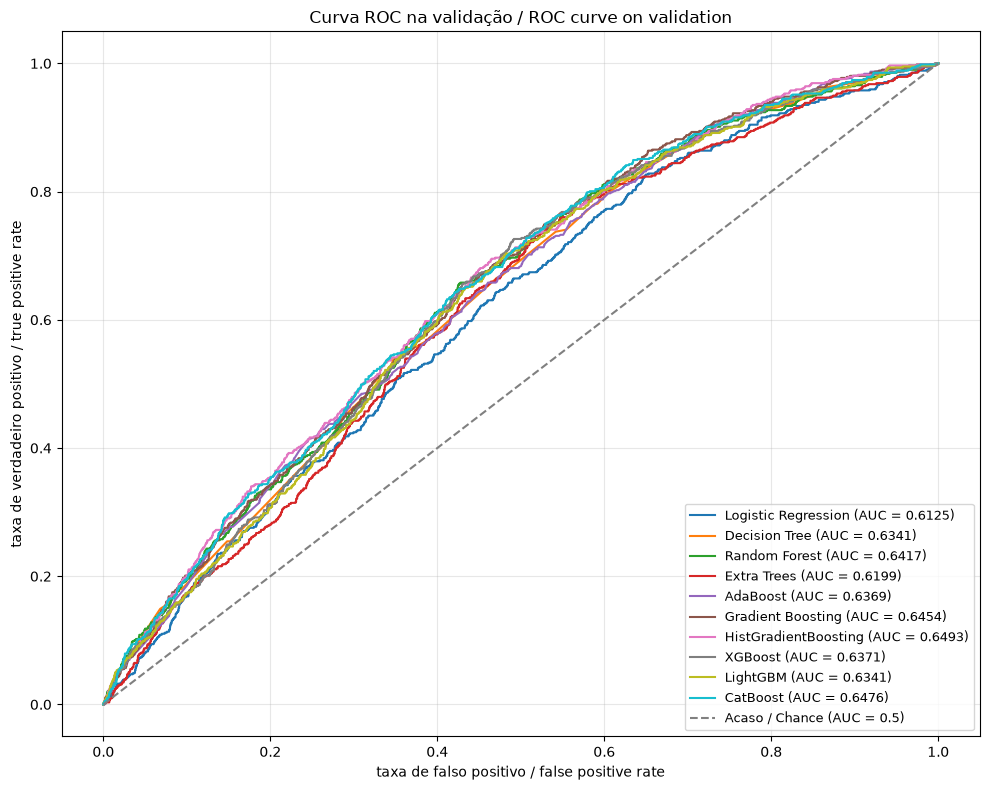

In [ ]:
"""ROC curve for all models / curva ROC de todos os modelos."""

# single plot with one curve per model / gráfico único com uma curva por modelo
fig, eixo = plt.subplots(figsize=(10, 8))

for nome in modelos:
    # validation probabilities saved in the training loop / probabilidades da validação salvas no loop de treino
    proba = probas_val[nome]

    # false positive rate and true positive rate across thresholds / taxa de falso positivo e verdadeiro positivo em todos os limiares
    fpr, tpr, _ = roc_curve(y_val, proba)
    area = auc(fpr, tpr)

    # curve with the AUC in the legend / curva com a AUC na legenda
    eixo.plot(fpr, tpr, linewidth=1.5, label=f"{nome} (AUC = {area:.4f})")

# diagonal is the chance level / diagonal é o nível do acaso
eixo.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acaso / Chance (AUC = 0.5)")

eixo.set_xlabel("taxa de falso positivo / false positive rate")
eixo.set_ylabel("taxa de verdadeiro positivo / true positive rate")
eixo.set_title("Curva ROC na validação / ROC curve on validation")
eixo.legend(loc="lower right", fontsize=9)
eixo.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Part 11 - Save models

In [ ]:
"""Save all trained models / salva todos os modelos treinados."""

# output folder for the models / pasta de saída dos modelos
pasta_modelos = Path(r"..\models")
pasta_modelos.mkdir(parents=True, exist_ok=True)

caminhos = {}

for nome, modelo in modelos.items():
    # safe file name from the model name / nome de arquivo seguro a partir do nome do modelo
    arquivo = pasta_modelos / f"{nome.lower().replace(' ', '_')}.joblib"

    # serialize the fitted model / serializa o modelo treinado
    joblib.dump(modelo, arquivo)
    caminhos[nome] = arquivo

    # confirm the saved file and its size / confirma o arquivo salvo e o tamanho
    print(f"{nome}: {arquivo} ({arquivo.stat().st_size / 1024:.1f} KB)")

Logistic Regression: ..\models\logistic_regression.joblib (3.6 KB)
Decision Tree: ..\models\decision_tree.joblib (10.5 KB)
Random Forest: ..\models\random_forest.joblib (5040.0 KB)
Extra Trees: ..\models\extra_trees.joblib (4480.3 KB)
AdaBoost: ..\models\adaboost.joblib (127.3 KB)
Gradient Boosting: ..\models\gradient_boosting.joblib (260.7 KB)
HistGradientBoosting: ..\models\histgradientboosting.joblib (152.2 KB)
XGBoost: ..\models\xgboost.joblib (491.8 KB)
LightGBM: ..\models\lightgbm.joblib (517.0 KB)
CatBoost: ..\models\catboost.joblib (106.0 KB)


In [73]:
"""Save the feature names with the models / salva os nomes das variáveis junto com os modelos."""

# columns used at fit time, in order / colunas usadas no treino, em ordem
joblib.dump(list(X_tr.columns), pasta_modelos / "colunas.joblib")

# validation probabilities and results table / probabilidades da validação e tabela de resultados
joblib.dump(probas_val, pasta_modelos / "probas_val.joblib")
tabela.to_csv(pasta_modelos / "resultados_modelos.csv", index=False)

# Part 12 - Resultado final models

In [ ]:
"""Check the kernel environment / confere o ambiente do kernel."""

# path of the Python running this notebook / caminho do Python que roda este notebook
print(sys.executable)

# should print a version, not raise an error / deve imprimir uma versão, não dar erro
import jinja2
print(jinja2.__version__)

c:\Users\rafae\Documents\Projetos_data_science_IA\machine_learning\Car Insurance Claim Prediction\.venv\Scripts\python.exe
3.1.6


In [80]:
"""Final model results with yellow highlight / resultado final dos modelos com destaque amarelo."""

# columns where higher is better / colunas em que maior é melhor
colunas_max = ["roc_auc", "pr_auc", "acuracia", "acuracia_balanceada", "recall", "precisao", "f1", "lift"]

# columns where lower is better / colunas em que menor é melhor
colunas_min = ["segundos"]

# final table ordered by PR-AUC / tabela final ordenada por PR-AUC
final = tabela.sort_values("pr_auc", ascending=False).reset_index(drop=True)

# yellow on the best value of each column / amarelo no melhor valor de cada coluna
final_estilo = (
    final.style
    .highlight_max(subset=colunas_max, color="yellow")
    .highlight_min(subset=colunas_min, color="yellow")
    .format({coluna: "{:.4f}" for coluna in colunas_max + ["brier"]})
    .format({"segundos": "{:.2f}"})
    .set_caption("Resultado final dos modelos na validação / final model results on validation")
)

"""Highlight the whole row of the best model / destaca a linha inteira do melhor modelo."""

# best model by PR-AUC / melhor modelo por PR-AUC
melhor = final.loc[final["pr_auc"].idxmax(), "modelo"]

# yellow background on the best row / fundo amarelo na linha do melhor modelo
final_linha = final.style.apply(
    lambda linha: ["background-color: yellow; color: black" if linha["modelo"] == melhor else "" for _ in linha],
    axis=1,
).format({coluna: "{:.4f}" for coluna in colunas_max + ["brier"]}).format({"segundos": "{:.2f}"})

# show the styled table / mostra a tabela estilizada
final_linha

,modelo,roc_auc,pr_auc,acuracia,acuracia_balanceada,recall,precisao,f1,brier,segundos,lift
0,HistGradientBoosting,0.649346,0.107140,0.779627,0.577725,0.345219,0.113600,0.170947,0.224094,1.40,1.726094
1,CatBoost,0.647571,0.106214,0.779413,0.576857,0.343598,0.113067,0.170144,0.221706,3.74,1.717990
2,Random Forest,0.641658,0.105501,0.777920,0.570785,0.332253,0.109333,0.164526,0.223027,1.32,1.661264
3,Gradient Boosting,0.645426,0.104026,0.777920,0.570785,0.332253,0.109333,0.164526,0.060632,18.24,1.661264
4,LightGBM,0.634137,0.101761,0.773440,0.552568,0.298217,0.098133,0.147673,0.209752,1.40,1.491086
5,XGBoost,0.637063,0.100817,0.774080,0.555171,0.303079,0.099733,0.150080,0.212804,1.12,1.515397
6,AdaBoost,0.636905,0.100332,0.776640,0.565580,0.322528,0.106133,0.159711,0.087841,7.80,1.612642
7,Decision Tree,0.634081,0.099977,0.773013,0.550833,0.294976,0.097067,0.146067,0.229128,0.12,1.474878
8,Extra Trees,0.619937,0.091235,0.770667,0.541291,0.277147,0.091200,0.137239,0.236014,0.94,1.385737
9,Logistic Regression,0.612486,0.090586,0.773227,0.551701,0.296596,0.097600,0.146870,0.240075,0.13,1.482982
